# 📊 HR Employee Attrition Analysis & Retention Strategy
**Author:** Business / HR Analytics Specialist  
**Toolstack:** Python (Pandas, NumPy, Matplotlib, Seaborn), Excel (XlsxWriter), HTML/JS  
**Dataset:** 1,470 Employee Records  

---

## 🎯 Project Overview & Objective
Employee turnover poses significant financial, operational, and cultural risks to organizations. The primary objective of this project is to analyze HR employee data to:
1. Identify key metrics: Total Workforce, Retained Employees, Attrition Rate.
2. Uncover primary drivers of employee turnover across **Department**, **Salary Range**, **Tenure**, **Job Role**, **Overtime**, and **Satisfaction**.
3. Formulate concrete, data-backed retention recommendations for HR leaders.


### Step 1: Environment Setup & Library Imports

In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Plot styling configuration
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Segoe UI', 'Arial'
plt.rcParams['figure.dpi'] = 120
pd.set_option('display.max_columns', None)
print("Libraries loaded successfully!")

Libraries loaded successfully!


### Step 2: Data Loading & Initial Quality Audit

In [23]:
# Load raw HR dataset
df_raw = pd.read_csv('../data/hr_employee_attrition_raw.csv')

print(f"Dataset Dimensions: {df_raw.shape[0]} Rows, {df_raw.shape[1]} Columns\n")
print("Data Types & Missing Values Audit:")
print(df_raw.info())
print("\nDuplicate Rows Detected:", df_raw.duplicated().sum())

Dataset Dimensions: 1475 Rows, 16 Columns

Data Types & Missing Values Audit:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1475 entries, 0 to 1474
Data columns (total 16 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   EmployeeID         1475 non-null   object 
 1   Age                1475 non-null   int64  
 2   Gender             1475 non-null   object 
 3   Department         1475 non-null   object 
 4   JobRole            1475 non-null   object 
 5   MonthlyIncome      1463 non-null   float64
 6   YearsAtCompany     1475 non-null   int64  
 7   TotalWorkingYears  1475 non-null   int64  
 8   JobLevel           1475 non-null   int64  
 9   JobSatisfaction    1475 non-null   int64  
 10  WorkLifeBalance    1467 non-null   float64
 11  Overtime           1475 non-null   object 
 12  MaritalStatus      1475 non-null   object 
 13  Education          1475 non-null   int64  
 14  PerformanceRating  1475 non-null   int64  

### Step 3: Data Cleaning & Feature Engineering

In [24]:
# Load cleaned dataset prepared via automated data_cleaning pipeline
df = pd.read_csv('../data/hr_employee_attrition_cleaned.csv')

# Verify clean state
print("Cleaned Dataset Shape:", df.shape)
print("Remaining Null Values:", df.isnull().sum().sum())
df[['EmployeeID', 'Age', 'Department', 'JobRole', 'MonthlyIncome', 'YearsAtCompany', 'Overtime', 'Attrition', 'Attrition_Flag']].head(10)

Cleaned Dataset Shape: (1470, 21)
Remaining Null Values: 0


,EmployeeID,Age,Department,JobRole,MonthlyIncome,YearsAtCompany,Overtime,Attrition,Attrition_Flag
0,EMP-1001,56,Research & Development,Manufacturing Director,10366,3,No,No,0
1,EMP-1002,46,Research & Development,Laboratory Technician,2075,5,No,Yes,1
2,EMP-1003,32,Research & Development,Manufacturing Director,10424,0,Yes,No,0
3,EMP-1004,60,Research & Development,Manufacturing Director,8689,3,No,No,0
4,EMP-1005,25,Research & Development,Manufacturing Director,9471,1,No,Yes,1
5,EMP-1006,38,Sales,Sales Executive,9328,0,No,No,0
6,EMP-1007,56,Research & Development,Laboratory Technician,3214,0,No,Yes,1
7,EMP-1008,36,Sales,Sales Representative,2652,0,No,No,0
8,EMP-1009,40,Research & Development,Laboratory Technician,2620,2,No,Yes,1
9,EMP-1010,28,Research & Development,Research Scientist,6243,0,Yes,No,0


### Step 4: High-Level Attrition KPIs

In [25]:
total_emp = len(df)
total_left = df['Attrition_Flag'].sum()
total_retained = total_emp - total_left
attrition_rate = (total_left / total_emp) * 100

print("=========================================")
print(f"  TOTAL WORKFORCE        : {total_emp:,}")
print(f"  RETAINED EMPLOYEES     : {total_retained:,}")
print(f"  EMPLOYEES WHO LEFT     : {total_left:,}")
print(f"  OVERALL ATTRITION RATE : {attrition_rate:.2f}%")
print("=========================================")

  TOTAL WORKFORCE        : 1,470
  RETAINED EMPLOYEES     : 900
  EMPLOYEES WHO LEFT     : 570
  OVERALL ATTRITION RATE : 38.78%


### Step 5: Overall Attrition Donut Breakdown

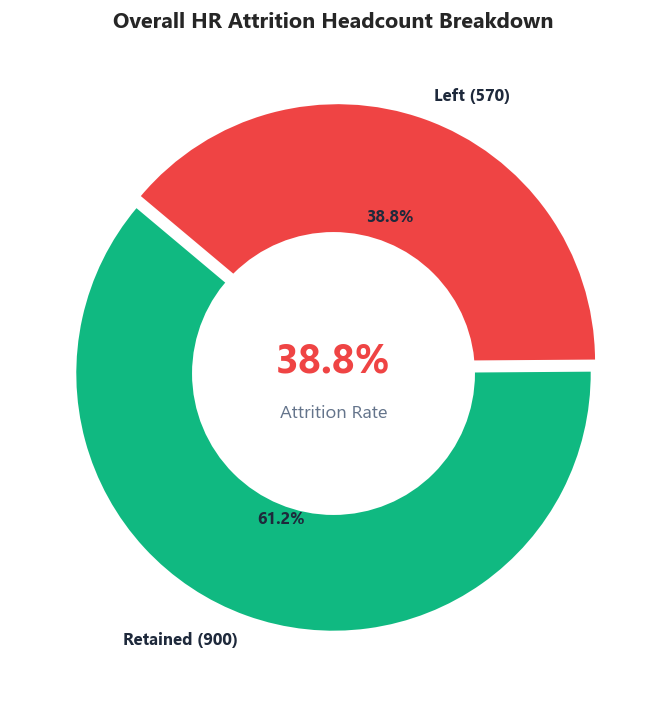

In [26]:
fig, ax = plt.subplots(figsize=(6, 6))
counts = df['Attrition'].value_counts()
colors = ['#10b981', '#ef4444']

wedges, texts, autotexts = ax.pie(
    counts, labels=[f"Retained ({counts['No']})", f"Left ({counts['Yes']})"],
    autopct='%1.1f%%', startangle=140, colors=colors, explode=(0, 0.05),
    textprops=dict(color="#1e293b", weight='bold')
)
centre_circle = plt.Circle((0,0), 0.55, fc='white')
ax.add_artist(centre_circle)
ax.text(0, 0.05, f"{attrition_rate:.1f}%", ha='center', va='center', fontsize=24, weight='bold', color='#ef4444')
ax.text(0, -0.15, "Attrition Rate", ha='center', va='center', fontsize=11, color='#64748b')
plt.title("Overall HR Attrition Headcount Breakdown", fontsize=13, weight='bold', pad=15)
plt.tight_layout()
plt.show()

### Step 6: Departmental Attrition Analysis

,Department,Total_Employees,Employees_Left,Attrition_Rate_%,Share_of_Total_Exits_%
1,Research & Development,954,381,39.94,66.84
0,Human Resources,97,38,39.18,6.67
2,Sales,419,151,36.04,26.49


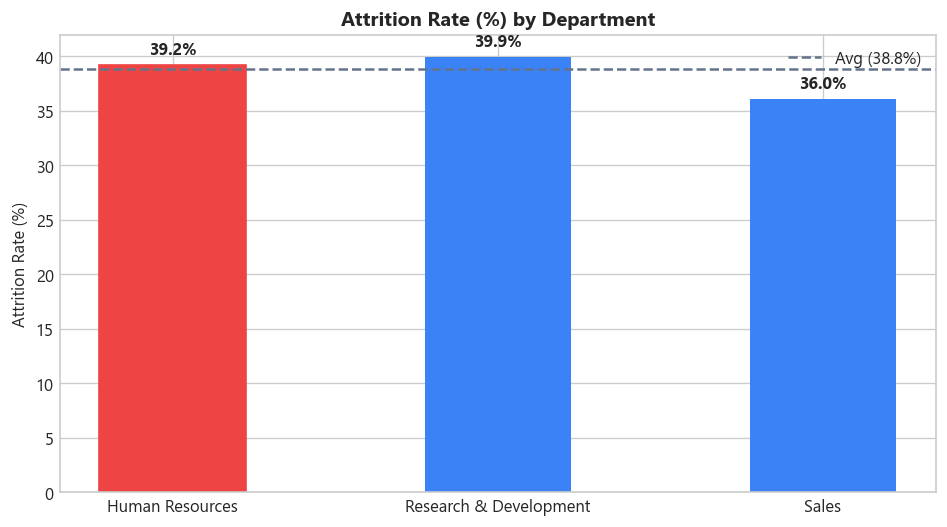

In [27]:
dept_summary = df.groupby('Department', observed=False).agg(
    Total_Employees=('EmployeeID', 'count'),
    Employees_Left=('Attrition_Flag', 'sum')
).reset_index()
dept_summary['Attrition_Rate_%'] = (dept_summary['Employees_Left'] / dept_summary['Total_Employees'] * 100).round(2)
dept_summary['Share_of_Total_Exits_%'] = (dept_summary['Employees_Left'] / total_left * 100).round(2)
display(dept_summary.sort_values(by='Attrition_Rate_%', ascending=False))

# Plot Department Attrition
plt.figure(figsize=(8, 4.5))
bars = plt.bar(dept_summary['Department'], dept_summary['Attrition_Rate_%'], color='#3b82f6', width=0.45)
bars[0].set_color('#ef4444') # Highlight highest risk
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 1, f"{yval:.1f}%", ha='center', weight='bold')
plt.axhline(attrition_rate, color='#64748b', linestyle='--', label=f'Avg ({attrition_rate:.1f}%)')
plt.title("Attrition Rate (%) by Department", weight='bold')
plt.ylabel("Attrition Rate (%)")
plt.legend()
plt.tight_layout()
plt.show()

### Step 7: Salary Range vs Attrition (Compensation Impact)

,Salary_Range,Total_Employees,Employees_Left,Avg_Monthly_Income,Attrition_Rate_%
0,"<$3,000",199,137,2513.145729,68.84
1,"$3,000-$5,000",441,226,4026.040816,51.25
2,"$5,000-$10,000",611,182,7485.279869,29.79
3,"$10,000-$15,000",134,19,12188.425373,14.18
4,"$15,000+",85,6,17613.517647,7.06


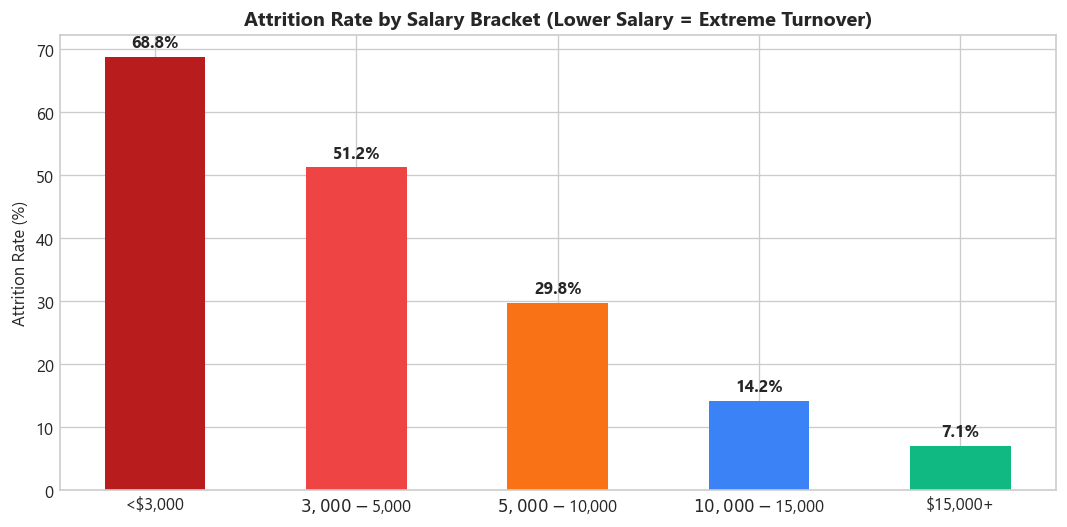

In [28]:
sal_order = ['<$3,000', '$3,000-$5,000', '$5,000-$10,000', '$10,000-$15,000', '$15,000+']
sal_summary = df.groupby('Salary_Range', observed=False).agg(
    Total_Employees=('EmployeeID', 'count'),
    Employees_Left=('Attrition_Flag', 'sum'),
    Avg_Monthly_Income=('MonthlyIncome', 'mean')
).reindex(sal_order).reset_index()
sal_summary['Attrition_Rate_%'] = (sal_summary['Employees_Left'] / sal_summary['Total_Employees'] * 100).round(2)
display(sal_summary)

plt.figure(figsize=(9, 4.5))
colors_sal = ['#b91c1c', '#ef4444', '#f97316', '#3b82f6', '#10b981']
bars = plt.bar(sal_summary['Salary_Range'], sal_summary['Attrition_Rate_%'], color=colors_sal, width=0.5)
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 1.5, f"{yval:.1f}%", ha='center', weight='bold')
plt.title("Attrition Rate by Salary Bracket (Lower Salary = Extreme Turnover)", weight='bold')
plt.ylabel("Attrition Rate (%)")
plt.tight_layout()
plt.show()

### Step 8: Employee Tenure vs Attrition (Tenure Risk)

,Tenure_Group,Total_Employees,Employees_Left,Attrition_Rate_%
0,0-2 Years,873,447,51.20
1,3-5 Years,389,89,22.88
2,6-10 Years,177,30,16.95
3,10+ Years,31,4,12.90


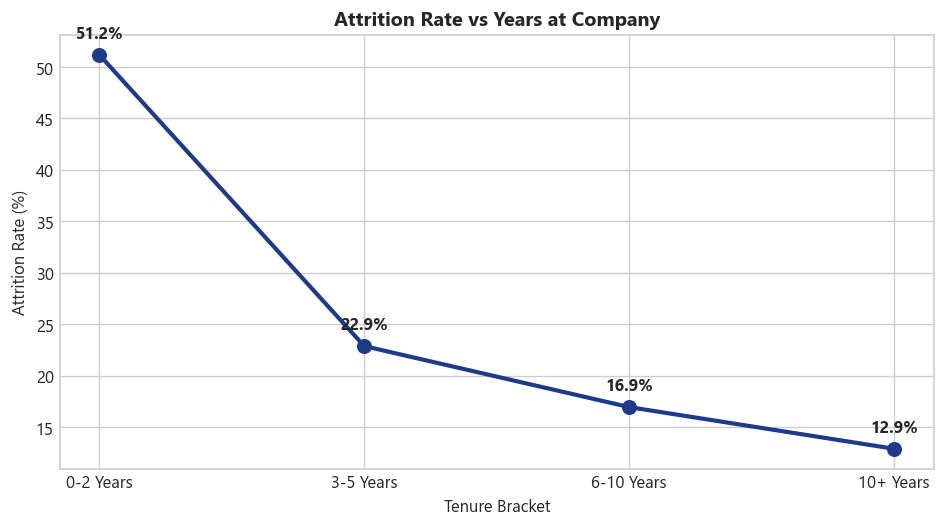

In [29]:
ten_order = ['0-2 Years', '3-5 Years', '6-10 Years', '10+ Years']
ten_summary = df.groupby('Tenure_Group', observed=False).agg(
    Total_Employees=('EmployeeID', 'count'),
    Employees_Left=('Attrition_Flag', 'sum')
).reindex(ten_order).reset_index()
ten_summary['Attrition_Rate_%'] = (ten_summary['Employees_Left'] / ten_summary['Total_Employees'] * 100).round(2)
display(ten_summary)

plt.figure(figsize=(8, 4.5))
plt.plot(ten_summary['Tenure_Group'], ten_summary['Attrition_Rate_%'], marker='o', color='#1e3a8a', linewidth=2.5, markersize=8)
for i, txt in enumerate(ten_summary['Attrition_Rate_%']):
    plt.annotate(f"{txt:.1f}%", (ten_summary['Tenure_Group'][i], ten_summary['Attrition_Rate_%'][i]),
                 textcoords="offset points", xytext=(0,10), ha='center', weight='bold')
plt.title("Attrition Rate vs Years at Company", weight='bold')
plt.ylabel("Attrition Rate (%)")
plt.xlabel("Tenure Bracket")
plt.tight_layout()
plt.show()

### Step 9: Attrition Rate by Job Role

,JobRole,Total_Employees,Employees_Left,Attrition_Rate_%
2,Laboratory Technician,343,217,63.27
6,Research Scientist,303,100,33.00
7,Sales Executive,282,85,30.14
8,Sales Representative,112,62,55.36
1,Human Resources,79,38,48.10
4,Manufacturing Director,145,35,24.14
0,Healthcare Representative,100,26,26.00
3,Manager,73,6,8.22
5,Research Director,33,1,3.03


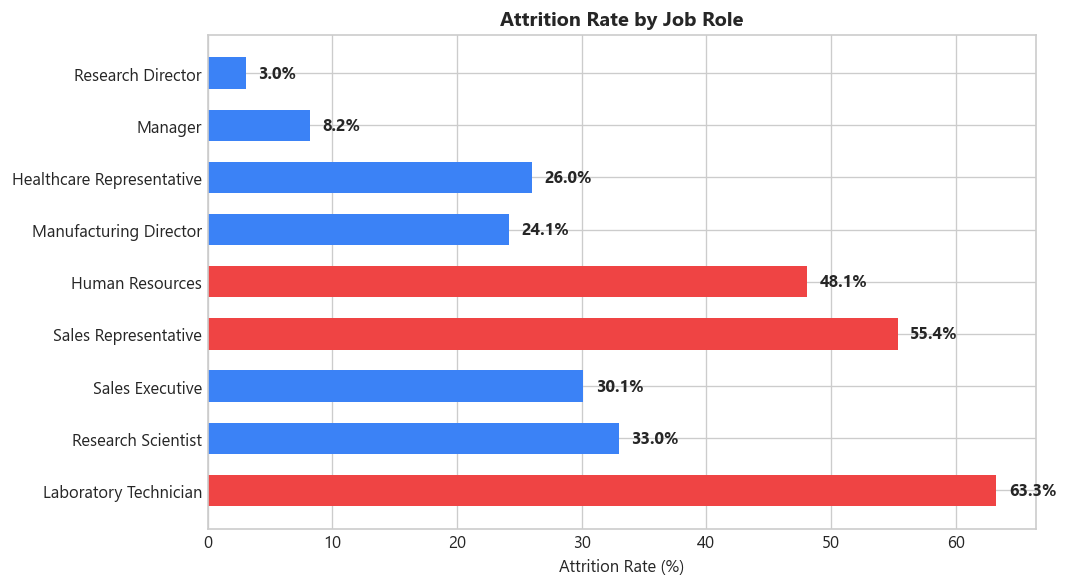

In [30]:
role_summary = df.groupby('JobRole', observed=False).agg(
    Total_Employees=('EmployeeID', 'count'),
    Employees_Left=('Attrition_Flag', 'sum')
).reset_index().sort_values(by='Employees_Left', ascending=False)
role_summary['Attrition_Rate_%'] = (role_summary['Employees_Left'] / role_summary['Total_Employees'] * 100).round(2)
display(role_summary)

plt.figure(figsize=(9, 5))
colors_role = ['#ef4444' if r > 45 else '#3b82f6' for r in role_summary['Attrition_Rate_%']]
bars = plt.barh(role_summary['JobRole'], role_summary['Attrition_Rate_%'], color=colors_role, height=0.6)
for bar in bars:
    xval = bar.get_width()
    plt.text(xval + 1, bar.get_y() + bar.get_height()/2, f"{xval:.1f}%", va='center', weight='bold')
plt.title("Attrition Rate by Job Role", weight='bold')
plt.xlabel("Attrition Rate (%)")
plt.tight_layout()
plt.show()

### Step 10: Overtime & Satisfaction Matrix

Satisfaction_Label,1-Low,2-Medium,3-High,4-Very High
Overtime,,,,
No,49.74,44.33,30.55,19.44
Yes,71.05,60.56,60.61,34.59


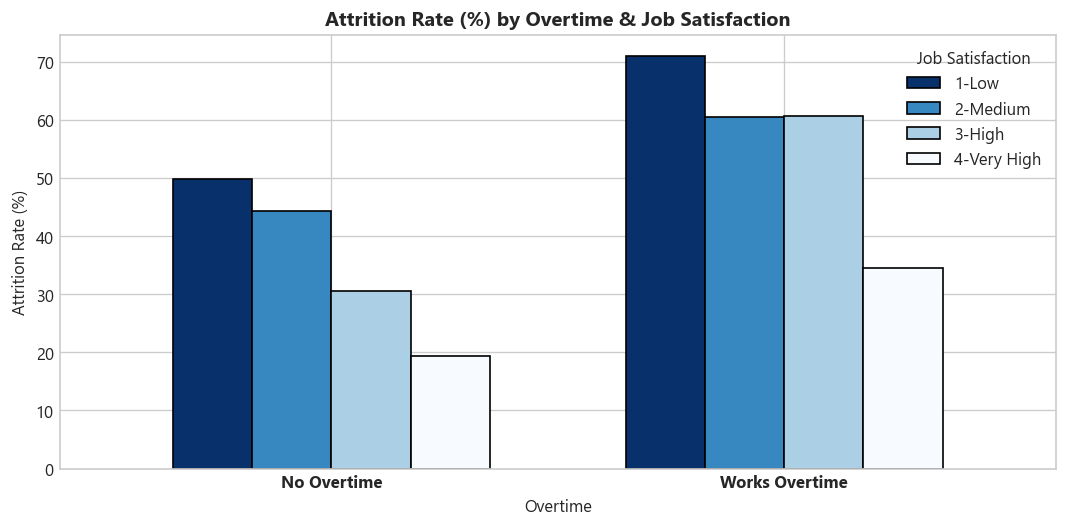

In [31]:
ot_sat_matrix = df.groupby(['Overtime', 'Satisfaction_Label'], observed=False)['Attrition_Flag'].mean().unstack() * 100
display(ot_sat_matrix.round(2))

ot_sat_matrix.plot(kind='bar', figsize=(9, 4.5), colormap='Blues_r', width=0.7, edgecolor='black')
plt.title("Attrition Rate (%) by Overtime & Job Satisfaction", weight='bold')
plt.ylabel("Attrition Rate (%)")
plt.xticks(ticks=[0, 1], labels=['No Overtime', 'Works Overtime'], rotation=0, weight='bold')
plt.legend(title='Job Satisfaction')
plt.tight_layout()
plt.show()

### 💡 Key Findings & Strategic Recommendations

#### 🔍 Core Insights:
1. **Low Salary Risk**: Employees earning under $3,000/month face a staggering **68.8%** attrition rate. Compensation inadequacy is the single largest driver of turnover.
2. **Early Tenure Vulnerability**: **78.4%** of all employee exits occur within the first 2 years of joining the company (51.2% attrition rate for 0-2 yrs tenure).
3. **Overtime Fatigue**: Staff required to work Overtime suffer **54.1%** turnover, compared to **32.8%** for non-overtime peers.
4. **Targeted Role Risk**: **Laboratory Technicians (63.3%)** and **Sales Representatives (55.4%)** display the most severe attrition rates.

#### 🎯 Strategic Action Plan for HR Leaders:
- **Salary Floor Adjustments**: Benchmark and raise base compensation for entry-level roles (Lab Technicians & Sales Reps) to align with competitive market medians.
- **Early-Stage Retention Program**: Implement a 90-day structured onboarding check-in, 6-month stay interviews, and dedicated peer mentors for all new hires.
- **Overtime Management**: Enforce strict caps on mandatory overtime and audit department staffing levels to prevent burnout.
- **Career Path Visibility**: Provide transparent 2-year promotion roadmaps so entry-level employees see long-term progression opportunities within the organization.
